In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

INPUT_DIR = Path("/kaggle/input")

files = {
    "GD": "gd_comparison.csv",
    "SGD": "sgd_comparison.csv",
    "Mini-Batch GD": "mbgd_comparison.csv",
    "RMSProp": "rmsprop_comparison.csv",
    "Adam": "adam_comparison.csv"
}

optimizer_data = {}

for optimizer, filename in files.items():

    matches = list(INPUT_DIR.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"{filename} not found. Add it to notebook inputs."
        )

    df = pd.read_csv(matches[0])
    df["Optimizer"] = optimizer

    optimizer_data[optimizer] = df

    print(f"{optimizer} loaded successfully!")


GD loaded successfully!
SGD loaded successfully!
Mini-Batch GD loaded successfully!
RMSProp loaded successfully!
Adam loaded successfully!


In [3]:

all_results = pd.concat(
    optimizer_data.values(),
    ignore_index=True
)

best_results = (
    all_results
    .sort_values("Macro F1", ascending=False)
    .groupby("Optimizer")
    .first()
    .reset_index()
)

best_results = best_results.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(best_results)


,Optimizer,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1,Final Loss,Training Time
0,SGD,RBF,0.913990,0.928945,0.923610,0.925508,0.914384,0.643381,40.226583
1,Mini-Batch GD,RBF,0.905869,0.923039,0.916284,0.918641,0.906560,0.703689,4.310315
2,GD,RBF,0.857143,0.895712,0.871277,0.873029,0.849561,1.301629,5.557293
3,Adam,Linear,0.812108,0.798233,0.835066,0.800808,0.804658,5.172619,1.710243
4,RMSProp,Linear,0.806940,0.780149,0.828468,0.790107,0.803391,4.876410,1.701653


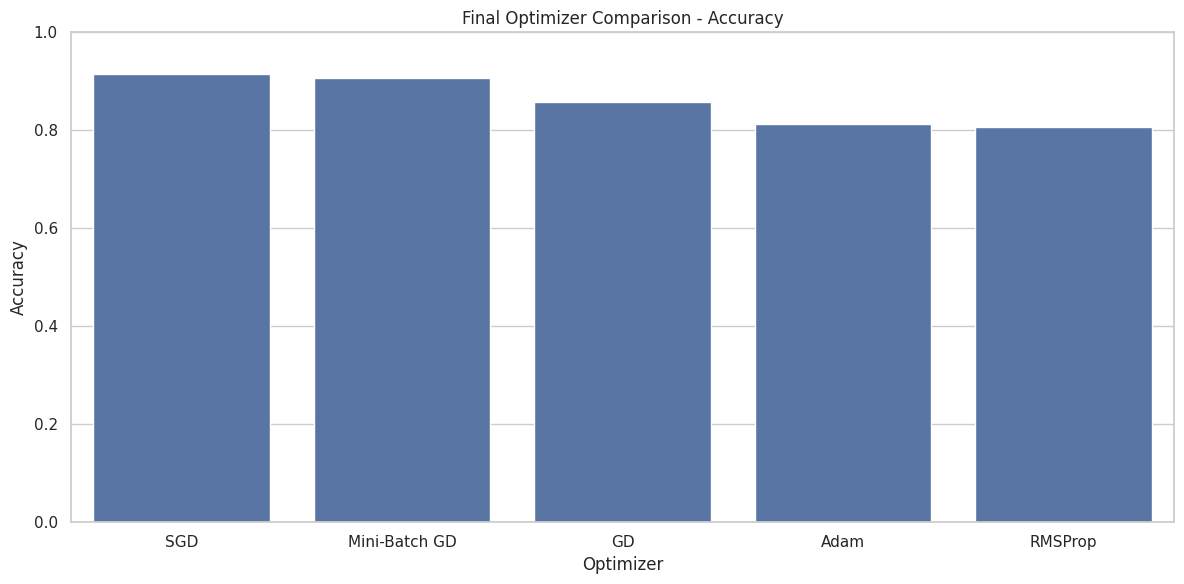

In [4]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=best_results,
    x="Optimizer",
    y="Accuracy"
)

plt.title("Final Optimizer Comparison - Accuracy")
plt.xlabel("Optimizer")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


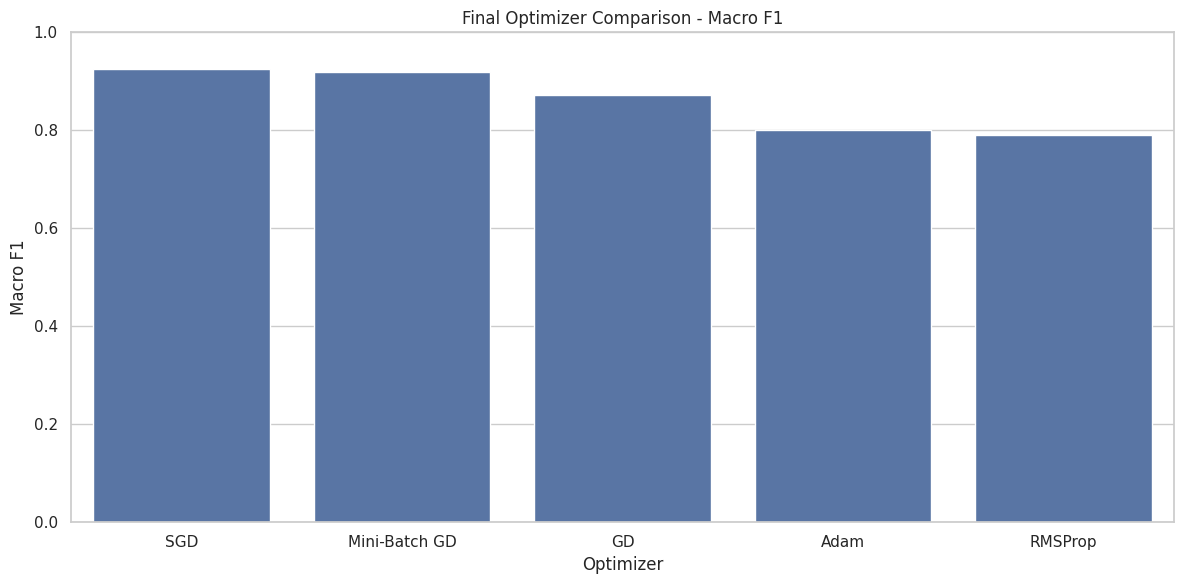

In [5]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=best_results,
    x="Optimizer",
    y="Macro F1"
)

plt.title("Final Optimizer Comparison - Macro F1")
plt.xlabel("Optimizer")
plt.ylabel("Macro F1")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


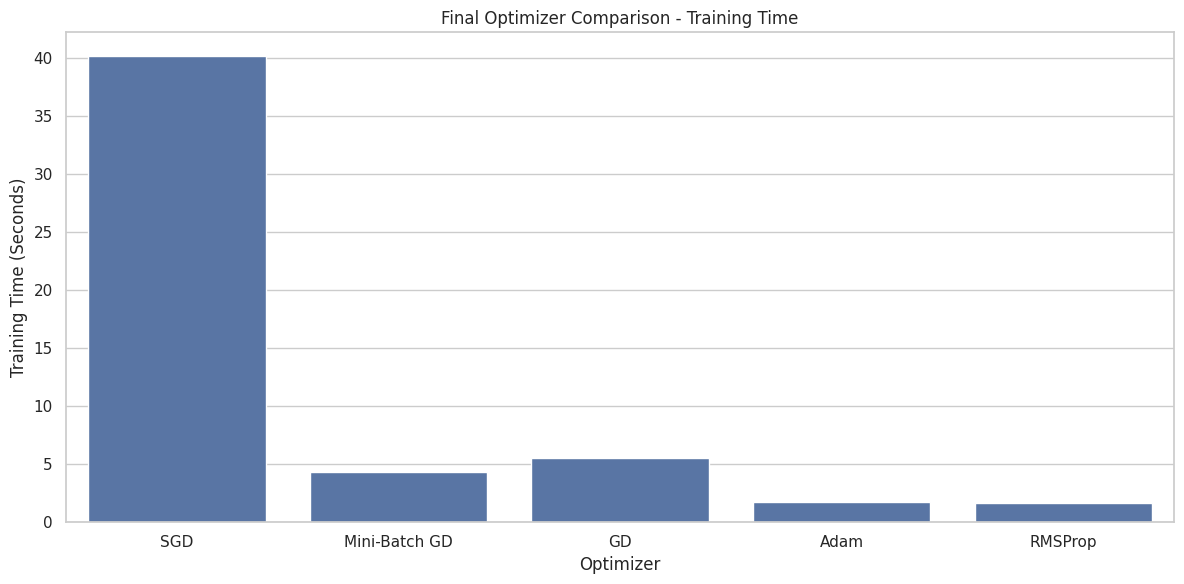

In [6]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=best_results,
    x="Optimizer",
    y="Training Time"
)

plt.title("Final Optimizer Comparison - Training Time")
plt.xlabel("Optimizer")
plt.ylabel("Training Time (Seconds)")

plt.tight_layout()
plt.show()


In [7]:

ranking = best_results[
    [
        "Optimizer",
        "Kernel",
        "Accuracy",
        "Precision",
        "Recall",
        "Macro F1",
        "Weighted F1",
        "Training Time"
    ]
].copy()

ranking = ranking.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

ranking.index += 1

print("FINAL OPTIMIZER RANKING")
display(ranking.round(4))

winner = ranking.iloc[0]

print("\nBest Optimizer:", winner["Optimizer"])
print("Best Kernel:", winner["Kernel"])
print("Best Macro F1:", round(winner["Macro F1"], 4))
print("Best Accuracy:", round(winner["Accuracy"], 4))


FINAL OPTIMIZER RANKING


,Optimizer,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1,Training Time
1,SGD,RBF,0.9140,0.9289,0.9236,0.9255,0.9144,40.2266
2,Mini-Batch GD,RBF,0.9059,0.9230,0.9163,0.9186,0.9066,4.3103
3,GD,RBF,0.8571,0.8957,0.8713,0.8730,0.8496,5.5573
4,Adam,Linear,0.8121,0.7982,0.8351,0.8008,0.8047,1.7102
5,RMSProp,Linear,0.8069,0.7801,0.8285,0.7901,0.8034,1.7017



Best Optimizer: SGD
Best Kernel: RBF
Best Macro F1: 0.9255
Best Accuracy: 0.914


In [8]:

OUTPUT_DIR = Path("/kaggle/working/final_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ranking.to_csv(
    OUTPUT_DIR / "final_optimizer_ranking.csv"
)

all_results.to_csv(
    OUTPUT_DIR / "all_kernel_results.csv",
    index=False
)

print("Final comparison saved successfully!")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


Final comparison saved successfully!
final_optimizer_ranking.csv
all_kernel_results.csv
